# Aşama 1 — Veri Ön İşleme ve MapReduce

**Veri:** Elliptic++ (Elmougy & Liu, KDD 2023). Bitcoin işlem grafı (203.769 işlem, 234.355 para akışı kenarı, 49 zaman adımı) ve cüzdan (aktör) grafı (822.942 adres).

Bu notebook iki iş yapar:
1. **Ön işleme (DataFrame API):** Ham CSV'lerdeki *gerçek* kusurları tespit eder, düzeltir ve her adımın veriye etkisini ölçer. Çıktılar `data/processed/` altına Parquet olarak yazılır; sonraki dört aşama bu temiz veriyi kullanır.
2. **MapReduce (RDD API):** `map` / `flatMap` / `reduceByKey` ile üç dağıtık hesap yapar ve `reduceByKey` ile `groupByKey` arasındaki shuffle farkını ölçer.

| Dosya | Satır | İçerik |
|---|---|---|
| `txs_features.csv` | 203.769 | txId, zaman adımı, 93 local + 72 aggregate (anonim) + 17 Elliptic++ özelliği |
| `txs_classes.csv` | 203.769 | 1 = illicit, 2 = licit, 3 = unknown |
| `txs_edgelist.csv` | 234.355 | txId1 → txId2 (BTC akışı) |
| `wallets_features.csv` | 1.268.260 | adres × zaman adımı, 55 davranış özelliği |
| `wallets_classes.csv` | 822.942 | adres sınıfı |
| `AddrAddr / AddrTx / TxAddr` | 2.87M / 477K / 837K | adres-adres, adres→işlem, işlem→adres kenarları |

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "common").is_dir())
sys.path.insert(0, str(ROOT))
from common.spark_utils import *  # get_spark, RAW, PROC, MODELS, CHECKPOINTS, TRAIN_MAX_STEP ...
import pandas as pd
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

In [2]:
from pyspark.sql import functions as F, types as T
import time

spark = get_spark("01-preprocessing-mapreduce")
sc = spark.sparkContext
print("Spark", spark.version, "| master:", sc.master, "| paralellik:", sc.defaultParallelism)
print("Spark UI:", sc.uiWebUrl)

:: loading settings :: url = jar:file:/usr/local/lib/python3.13/dist-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Spark 3.5.8 | master: local[*] | paralellik: 2
Spark UI: http://192.0.2.2:4040


## 1. Yükleme — açık şema ile

`inferSchema=True` tipleri tahmin etmek için 695 MB'lık dosyayı **iki kez** okur. Başlık satırından şemayı programatik olarak kurup tek okumada yüklüyoruz: `txId` → long, `Time step` → int, geri kalan 182 sütun → double.

In [3]:
def schema_from_header(path, overrides, default=T.DoubleType()):
    header = open(path, encoding="utf-8").readline().strip().split(",")
    return T.StructType([T.StructField(c, overrides.get(c, default), True) for c in header])

tx_schema = schema_from_header(RAW / "txs_features.csv", {"txId": T.LongType(), "Time step": T.IntegerType()})
w_schema  = schema_from_header(RAW / "wallets_features.csv", {"address": T.StringType(), "Time step": T.IntegerType()})

csv = lambda name, schema: spark.read.csv(str(RAW / name), header=True, schema=schema)
txs_raw          = csv("txs_features.csv", tx_schema)
tx_classes_raw   = csv("txs_classes.csv", "txId LONG, class INT")
tx_edges_raw     = csv("txs_edgelist.csv", "txId1 LONG, txId2 LONG")
wallets_raw      = csv("wallets_features.csv", w_schema)
w_classes_raw    = csv("wallets_classes.csv", "address STRING, class INT")
addr_addr_raw    = csv("AddrAddr_edgelist.csv", "input_address STRING, output_address STRING")
addr_tx_raw      = csv("AddrTx_edgelist.csv", "input_address STRING, txId LONG")
tx_addr_raw      = csv("TxAddr_edgelist.csv", "txId LONG, output_address STRING")

raw = {"txs_features": txs_raw, "txs_classes": tx_classes_raw, "txs_edgelist": tx_edges_raw,
       "wallets_features": wallets_raw, "wallets_classes": w_classes_raw,
       "AddrAddr": addr_addr_raw, "AddrTx": addr_tx_raw, "TxAddr": tx_addr_raw}
overview = pd.DataFrame([{"tablo": k, "satır": df.count(), "sütun": len(df.columns)} for k, df in raw.items()])
overview

,tablo,satır,sütun
0,txs_features,203769,184
1,txs_classes,203769,2
2,txs_edgelist,234355,2
3,wallets_features,1268260,57
4,wallets_classes,822942,2
5,AddrAddr,2868964,2
6,AddrTx,477117,2
7,TxAddr,837124,2


In [4]:
txs_raw.select("txId", "Time step", "Local_feature_1", "Aggregate_feature_1", "in_txs_degree",
               "total_BTC", "fees", "size", "num_input_addresses").show(5)

+-----+---------+-------------------+-------------------+-------------+------------+------+--------+-------------------+
| txId|Time step|    Local_feature_1|Aggregate_feature_1|in_txs_degree|   total_BTC|  fees|    size|num_input_addresses|
+-----+---------+-------------------+-------------------+-------------+------------+------+--------+-------------------+
| 3321|        1|-0.1696145998853753|-0.1682452052985263|          1.0|  0.53397248|1.0E-4|   225.0|                1.0|
|11108|        1|-0.1375859782492397|-0.1475546102979693|          1.0|  5.61177786|1.0E-4|   225.0|                1.0|
|51816|        1|-0.1701032099368012| -0.169177511071022|          1.0|  0.45650843|1.0E-4|   226.0|                1.0|
|68869|        1|-0.1142667459350472|-0.1694183901410557|          0.0|      9.3088|1.0E-4|   853.0|                3.0|
|89273|        1|   5.20210716810059| 10.440725318381087|          1.0|852.16467964|   0.0|445268.0|                1.0|
+-----+---------+---------------

## 2. Veri kalitesi profili

Her sütun için null sayısı tek bir `agg` ile hesaplanır (184 sütun için 184 ayrı job yerine tek geçiş).

In [5]:
def null_counts(df):
    row = df.agg(*[F.sum(F.col(f"`{c}`").isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
    return {k: v for k, v in row.items() if v}

tx_nulls = null_counts(txs_raw)
print(f"txs_features: {len(tx_nulls)} sütunda null var")
pd.Series(tx_nulls, name="null").to_frame().T

txs_features: 17 sütunda null var


,in_txs_degree,out_txs_degree,total_BTC,fees,size,num_input_addresses,num_output_addresses,in_BTC_min,in_BTC_max,in_BTC_mean,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total
null,965,965,965,965,965,965,965,965,965,965,965,965,965,965,965,965,965


In [6]:
aug_cols = list(tx_nulls)                       # Elliptic++'ın eklediği 17 özellik
any_null = F.greatest(*[F.col(c).isNull().cast("int") for c in aug_cols]) == 1
all_null = F.least(*[F.col(c).isNull().cast("int") for c in aug_cols]) == 1
print("en az bir aug özelliği null olan satır :", txs_raw.filter(any_null).count())
print("17 aug özelliğinin HEPSİ null olan satır:", txs_raw.filter(all_null).count())
(txs_raw.filter(all_null).join(tx_classes_raw, "txId")
        .groupBy("class").count().orderBy("class").show())

en az bir aug özelliği null olan satır : 965


17 aug özelliğinin HEPSİ null olan satır: 965


+-----+-----+
|class|count|
+-----+-----+
|    2|  519|
|    3|  446|
+-----+-----+



**Bulgu:** 965 işlemde Elliptic++'ın blok zincirinden kazıdığı 17 özelliğin tamamı birlikte eksik; yani bu kayıtlar rastgele bozulmamış, zenginleştirme adımı o işlemler için hiç çalışmamış. Bu kayıtların hiçbiri illicit değil.

**Karar:** Satırları silmiyoruz (graf ve streaming aşamaları tüm düğümlere ihtiyaç duyuyor). Bunun yerine `aug_missing` göstergesi ekliyoruz. Değer doldurma (median imputation) **Aşama 2'deki ML pipeline'ının içinde, yalnızca eğitim verisine fit edilerek** yapılıyor. Burada global medyanla doldursaydık test döneminin istatistiği eğitime sızardı. Aşağıda imputasyonun etkisi gösterim amacıyla hesaplanıyor.

In [7]:
from pyspark.ml.feature import Imputer
demo_cols = ["fees", "size", "num_output_addresses"]
imp = Imputer(inputCols=demo_cols, outputCols=[c + "_imp" for c in demo_cols], strategy="median").fit(txs_raw)
before_after = (imp.transform(txs_raw)
    .agg(*[F.count(c).alias(f"{c} (dolu)") for c in demo_cols],
         *[F.count(c + "_imp").alias(f"{c}_imp (dolu)") for c in demo_cols],
         *[F.round(F.mean(c), 6).alias(f"{c} ort.") for c in demo_cols],
         *[F.round(F.mean(c + "_imp"), 6).alias(f"{c}_imp ort.") for c in demo_cols]))
before_after.toPandas().T.rename(columns={0: "değer"})

,değer
fees (dolu),202804.000000
size (dolu),202804.000000
num_output_addresses (dolu),202804.000000
fees_imp (dolu),203769.000000
size_imp (dolu),203769.000000
num_output_addresses_imp (dolu),203769.000000
fees ort.,0.000813
size ort.,596.937437
num_output_addresses ort.,4.216746
fees_imp ort.,0.000810


### 2.1 Tutarlılık kontrolleri: hatalı ve gereksiz veri

* Muhasebe kuralı: `in_BTC_total − out_BTC_total = fees` olmalı.
* `total_BTC` ile `out_BTC_total` aynı bilgiyi taşıyor olabilir.

In [8]:
chk = txs_raw.filter(~any_null).select(
    F.sum((F.abs(F.col("in_BTC_total") - F.col("out_BTC_total") - F.col("fees")) > 1e-6).cast("int")).alias("muhasebe_ihlali"),
    F.sum((F.abs(F.col("total_BTC") - F.col("out_BTC_total")) > 1e-9).cast("int")).alias("total_BTC != out_BTC_total"),
    F.count("*").alias("kontrol_edilen"),
    F.sum((F.col("fees") < 0).cast("int")).alias("negatif_ücret"),
    F.sum((F.col("size") <= 0).cast("int")).alias("boyut<=0"))
chk.show()

+---------------+--------------------------+--------------+-------------+--------+
|muhasebe_ihlali|total_BTC != out_BTC_total|kontrol_edilen|negatif_ücret|boyut<=0|
+---------------+--------------------------+--------------+-------------+--------+
|              0|                         0|        202804|            0|       0|
+---------------+--------------------------+--------------+-------------+--------+



**Bulgu:** Muhasebe kuralı tüm kayıtlarda sağlanıyor (fark < 1e-6), negatif ya da sıfır değer yok. Buna karşılık `total_BTC`, 202.804 kaydın **hepsinde** `out_BTC_total` ile aynı. Bu yüzden `total_BTC` sütununu çıkarıyoruz. Gereksiz (collinear) bir sütun ağaç modellerinde önem skorunu iki sütuna bölüp yorumu bulandırır.

### 2.2 Anonim özellikler zaten standardize mi?

In [9]:
probe = ["Local_feature_1", "Local_feature_50", "Aggregate_feature_1", "Aggregate_feature_40", "size", "fees"]
txs_raw.select(*[F.round(F.mean(c), 3).alias(c + "_μ") for c in probe],
               *[F.round(F.stddev(c), 3).alias(c + "_σ") for c in probe]).toPandas().T.rename(columns={0: ""})

,
Local_feature_1_μ,0.000
Local_feature_50_μ,0.000
Aggregate_feature_1_μ,0.000
Aggregate_feature_40_μ,0.000
size_μ,596.937
fees_μ,0.001
Local_feature_1_σ,1.000
Local_feature_50_σ,1.000
Aggregate_feature_1_σ,1.000
Aggregate_feature_40_σ,1.000


**Bulgu:** Local/Aggregate özellikler veri sahibi tarafından zaten z-skora çevrilmiş (μ≈0, σ≈1). Elliptic++ özellikleri ise ham ölçekte ve sağa çarpık (`size` için σ, ortalamanın yaklaşık 5 katı). BTC miktarlarını önce satoshi'ye çevirip (×10⁸) `log1p` uyguluyoruz. BTC cinsinden 0.0001 gibi küçük değerlerde `log1p(x) ≈ x` olduğundan, birim dönüşümü yapılmazsa logaritma çarpıklığı neredeyse hiç düşürmez. Ölçeklendirme (StandardScaler) yalnızca buna duyarlı olan Logistic Regression pipeline'ında yapılıyor; ağaç modelleri monoton dönüşümlerden etkilenmez.

### 2.3 Temizleme ve dönüştürme

In [10]:
def norm(c):  # "Time step" -> time_step, "num_txs_as receiver" -> num_txs_as_receiver
    return "time_step" if c == "Time step" else c.strip().replace(" ", "_")

btc_cols = [c for c in aug_cols if "BTC" in c and c != "total_BTC"] + ["fees"]

txs = (txs_raw
    .toDF(*[norm(c) for c in txs_raw.columns])
    .drop("total_BTC")
    .withColumn("aug_missing", F.col("fees").isNull().cast("int"))
    .withColumn("fee_rate_sat_b", F.col("fees") * 1e8 / F.col("size"))          # satoshi / byte
    .select("*", *[F.log1p(F.col(c) * 1e8).alias("log_" + c) for c in btc_cols]))   # satoshi ölçeğinde log

classes = (tx_classes_raw
    .withColumn("class_name", F.element_at(F.array(F.lit("illicit"), F.lit("licit"), F.lit("unknown")), F.col("class")))
    .withColumn("label", F.when(F.col("class") == 1, 1.0).when(F.col("class") == 2, 0.0)))   # unknown -> null
txs = txs.join(classes, "txId", "left")
print(len(txs.columns), "sütun")
txs.select("txId", "time_step", "class_name", "label", "aug_missing", "fees", "fee_rate_sat_b", "log_fees").show(5)

199 sütun


+-----+---------+----------+-----+-----------+------+------------------+-----------------+
| txId|time_step|class_name|label|aug_missing|  fees|    fee_rate_sat_b|         log_fees|
+-----+---------+----------+-----+-----------+------+------------------+-----------------+
| 3321|        1|   unknown| NULL|          0|1.0E-4| 44.44444444444444|9.210440366976517|
|11108|        1|   unknown| NULL|          0|1.0E-4| 44.44444444444444|9.210440366976517|
|51816|        1|   unknown| NULL|          0|1.0E-4| 44.24778761061947|9.210440366976517|
|68869|        1|     licit|  0.0|          0|1.0E-4|11.723329425556859|9.210440366976517|
|89273|        1|     licit|  0.0|          0|   0.0|               0.0|              0.0|
+-----+---------+----------+-----+-----------+------+------------------+-----------------+
only showing top 5 rows



In [11]:
skew_cols = ["fees", "in_BTC_total", "out_BTC_total", "in_BTC_max"]
sk = txs.select(*[F.skewness(c).alias(c) for c in skew_cols],
                *[F.skewness("log_" + c).alias("log_" + c) for c in skew_cols]).first().asDict()
pd.DataFrame({"önce (ham)": [sk[c] for c in skew_cols], "sonra (log1p)": [sk["log_" + c] for c in skew_cols]},
             index=skew_cols).round(2)

,önce (ham),sonra (log1p)
fees,21.47,0.55
in_BTC_total,26.72,0.17
out_BTC_total,26.72,0.13
in_BTC_max,27.21,0.16


### 2.4 Tekrarlanan kayıtlar ve graf kenarı temizliği

In [12]:
effects = []
def log_effect(step, before_df, after_df):
    b, a = before_df.count(), after_df.count()
    effects.append({"adım": step, "önce": b, "sonra": a, "çıkarılan": b - a, "oran %": round(100 * (b - a) / b, 2)})

# işlemler
log_effect("txs: tam satır tekrarı", txs_raw, txs_raw.dropDuplicates())
log_effect("txs: txId tekrarı", txs_raw, txs_raw.dropDuplicates(["txId"]))

# işlem kenarları
tx_edges = tx_edges_raw.toDF("src", "dst")
log_effect("tx kenar: tekrar + self-loop", tx_edges, tx_edges.dropDuplicates().filter("src != dst"))
tx_edges = tx_edges.dropDuplicates().filter("src != dst")

# cüzdanlar
wallets_n = wallets_raw.toDF(*[norm(c) for c in wallets_raw.columns])
wallets = wallets_n.dropDuplicates()
log_effect("wallets: tam satır tekrarı", wallets_n, wallets)
log_effect("wallets: (address, time_step) tekrarı (temizlik sonrası)", wallets, wallets.dropDuplicates(["address", "time_step"]))

# adres-adres kenarları
aa = addr_addr_raw.toDF("src", "dst")
aa_dedup = aa.dropDuplicates()
log_effect("AddrAddr: kenar tekrarı", aa, aa_dedup)
addr_edges = aa_dedup.filter("src != dst")
log_effect("AddrAddr: self-loop", aa_dedup, addr_edges)

addr_tx = addr_tx_raw.withColumnRenamed("input_address", "address").dropDuplicates()
tx_addr = tx_addr_raw.withColumnRenamed("output_address", "address").dropDuplicates()
log_effect("AddrTx: tekrar", addr_tx_raw, addr_tx)
log_effect("TxAddr: tekrar", tx_addr_raw, tx_addr)

w_classes = (w_classes_raw.dropDuplicates(["address"])
    .withColumn("class_name", F.element_at(F.array(F.lit("illicit"), F.lit("licit"), F.lit("unknown")), F.col("class")))
    .withColumn("label", F.when(F.col("class") == 1, 1.0).when(F.col("class") == 2, 0.0)))
pd.DataFrame(effects)

,adım,önce,sonra,çıkarılan,oran %
0,txs: tam satır tekrarı,203769,203769,0,0.00
1,txs: txId tekrarı,203769,203769,0,0.00
2,tx kenar: tekrar + self-loop,234355,234355,0,0.00
3,wallets: tam satır tekrarı,1268260,920691,347569,27.41
4,"wallets: (address, time_step) tekrarı (temizli...",920691,920691,0,0.00
5,AddrAddr: kenar tekrarı,2868964,2784344,84620,2.95
6,AddrAddr: self-loop,2784344,2775637,8707,0.31
7,AddrTx: tekrar,477117,477117,0,0.00
8,TxAddr: tekrar,837124,837124,0,0.00


**Bulgular:**
* İşlem tablosu temiz: tekrar yok.
* `wallets_features` satırlarının **%27'si birebir kopya**. Aynı (adres, zaman adımı) satırı birden fazla kez yazılmış; büyük ihtimalle kaynak birleştirme hatası. Temizlik sonrasında (adres, zaman adımı) anahtarı tekil hale geliyor, dolayısıyla tam-satır tekrarı ile anahtar tekrarı aynı şey çıkıyor.
* Adres grafındaki tekrarlı kenarlar PageRank ve derece hesabını şişirir. Self-loop'lar (kendine para gönderen adres, genelde para üstü) graf algoritmalarında gürültüdür; ikisini de çıkarıyoruz.

In [13]:
from pyspark.sql.window import Window
label_dist = (txs.groupBy("class_name").count()
    .withColumn("oran %", F.round(100 * F.col("count") / F.sum("count").over(Window.partitionBy()), 2))
    .orderBy("class_name"))
label_dist.show()

+----------+------+------+
|class_name| count|oran %|
+----------+------+------+
|   illicit|  4545|  2.23|
|     licit| 42019| 20.62|
|   unknown|157205| 77.15|
+----------+------+------+



Etiketli verinin yalnızca %9.8'i illicit; ayrıca işlemlerin %77'si etiketsiz. ML aşamasında yalnızca etiketli kayıtlar kullanılacak ve sınıf dengesizliği ağırlıklandırmayla ele alınacak.

### 2.5 Parquet'e yazma

CSV (metin, satır bazlı, şemasız) yerine Parquet (sütunsal, sıkıştırılmış, şemalı) kullanıyoruz. Sonraki aşamalar yalnızca ihtiyaç duydukları sütunları okur (column pruning) ve filtreler dosya seviyesine iner (predicate pushdown).

In [14]:
import shutil
t0 = time.time()
outputs = {"txs": txs, "tx_edges": tx_edges, "wallets": wallets, "wallet_classes": w_classes,
           "addr_edges": addr_edges, "addr_tx": addr_tx, "tx_addr": tx_addr}
for name, df in outputs.items():
    df.write.mode("overwrite").parquet(str(PROC / name))

def du(p):
    return sum(f.stat().st_size for f in p.rglob("*.parquet")) / 1e6
raw_sizes = {"txs": "txs_features.csv", "wallets": "wallets_features.csv", "addr_edges": "AddrAddr_edgelist.csv"}
pd.DataFrame([{"tablo": k, "parquet MB": round(du(PROC / k), 1),
               "ham CSV MB": round((RAW / raw_sizes[k]).stat().st_size / 1e6, 1) if k in raw_sizes else None}
              for k in outputs]).assign(süre_sn=round(time.time() - t0, 1))

,tablo,parquet MB,ham CSV MB,süre_sn
0,txs,123.5,694.8,95.5
1,tx_edges,2.3,NaN,95.5
2,wallets,179.1,606.5,95.5
3,wallet_classes,28.7,NaN,95.5
4,addr_edges,114.2,200.6,95.5
5,addr_tx,18.2,NaN,95.5
6,tx_addr,31.7,NaN,95.5


---
# B. MapReduce (RDD API)

Spark'ta MapReduce iki aşamadan oluşur:
* **Map:** Her partition'da **yerel** çalışır, shuffle gerektirmez. `map` her kayıttan tek bir (anahtar, değer) çifti üretir; `flatMap` sıfır ya da daha fazla çift üretebilir.
* **Reduce:** Aynı anahtarlı değerleri birleştirir. `reduceByKey` önce her partition içinde **yerel ön birleştirme (map-side combine)** yapar, ardından yalnızca kısmi sonuçları ağ üzerinden karıştırır (shuffle). `groupByKey` ise ön birleştirme yapmaz; her değeri tek tek shuffle'a gönderir.

## MR-1 · İşlem grafında in/out-degree (`flatMap` + `reduceByKey`)

Her kenar (u → v) iki kayıt yayar: `(u, (1, 0))` u için out-degree, `(v, (0, 1))` v için in-degree. Reduce aşaması bu vektörleri toplar.

In [15]:
edges_rdd = spark.read.parquet(str(PROC / "tx_edges")).rdd.map(lambda r: (r.src, r.dst))
print("partition sayısı:", edges_rdd.getNumPartitions())

degree_rdd = (edges_rdd
    .flatMap(lambda e: [(e[0], (1, 0)), (e[1], (0, 1))])          # MAP: 1 kenar -> 2 kayıt
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1])))         # REDUCE: (out, in) toplamı

print("lineage:\n" + degree_rdd.toDebugString().decode())
top_out = degree_rdd.takeOrdered(5, key=lambda kv: -kv[1][0])
top_in = degree_rdd.takeOrdered(5, key=lambda kv: -kv[1][1])
print("en yüksek out-degree:", top_out)
print("en yüksek in-degree :", top_in)

partition sayısı: 2
lineage:
(2) PythonRDD[386] at RDD at PythonRDD.scala:53 []
 |  MapPartitionsRDD[385] at mapPartitions at PythonRDD.scala:160 []
 |  ShuffledRDD[384] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(2) PairwiseRDD[383] at reduceByKey at /tmp/ipykernel_24132/85921668.py:6 []
    |  PythonRDD[382] at reduceByKey at /tmp/ipykernel_24132/85921668.py:6 []
    |  MapPartitionsRDD[381] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |  MapPartitionsRDD[380] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |  SQLExecutionRDD[379] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |  MapPartitionsRDD[378] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |  MapPartitionsRDD[377] at javaToPython at NativeMethodAccessorImpl.java:0 []
    |  FileScanRDD[376] at javaToPython at NativeMethodAccessorImpl.java:0 []


en yüksek out-degree: [(2984918, (472, 1)), (89273, (288, 1)), (102570, (122, 0)), (3181, (112, 1)), (7952, (99, 1))]
en yüksek in-degree : [(43388675, (0, 284)), (68705820, (0, 247)), (30699343, (0, 241)), (96576418, (0, 239)), (225859042, (0, 212))]


`toDebugString` çıktısındaki girinti, **stage sınırını** yani shuffle noktasını gösterir: `flatMap` ile `reduceByKey`'in yerel combine kısmı aynı stage'de çalışıyor, birleştirme ise shuffle'dan sonraki stage'de.

**Doğrulama:** Elliptic++'ın kendi `in_txs_degree` / `out_txs_degree` sütunlarıyla karşılaştırıyoruz.

In [16]:
deg_df = degree_rdd.map(lambda kv: (kv[0], kv[1][0], kv[1][1])).toDF(["txId", "out_mr", "in_mr"])
cmp = (txs.select("txId", "in_txs_degree", "out_txs_degree").join(deg_df, "txId", "left").fillna(0, ["in_mr", "out_mr"])
          .filter(F.col("in_txs_degree").isNotNull()))
cmp.select(F.count("*").alias("karşılaştırılan"),
           F.round(F.avg((F.col("in_mr") == F.col("in_txs_degree")).cast("int")), 4).alias("in eşleşme"),
           F.round(F.avg((F.col("out_mr") == F.col("out_txs_degree")).cast("int")), 4).alias("out eşleşme"),
           F.round(F.avg(F.col("in_txs_degree") - F.col("in_mr")), 3).alias("ort. in farkı"),
           F.round(F.avg(F.col("out_txs_degree") - F.col("out_mr")), 3).alias("ort. out farkı")).show()

+---------------+----------+-----------+-------------+--------------+
|karşılaştırılan|in eşleşme|out eşleşme|ort. in farkı|ort. out farkı|
+---------------+----------+-----------+-------------+--------------+
|         202804|       1.0|        1.0|          0.0|           0.0|
+---------------+----------+-----------+-------------+--------------+



MapReduce ile hesaplanan dereceler, veri setinin kendi `in_txs_degree` / `out_txs_degree` sütunlarıyla **%100 örtüşüyor**. Bu iki şeyi doğruluyor: (1) MR kodu doğru, (2) Elliptic++'ın degree özellikleri zincirin tamamından değil, bu edgelist'ten türetilmiş. Dolayısıyla Aşama 5'teki graf metrikleri ML özellikleriyle aynı grafı ölçüyor.

## MR-2 · Zaman adımı × sınıf sayımı (`map` + `reduceByKey`)

In [17]:
pairs = (spark.read.parquet(str(PROC / "txs")).select("time_step", "class_name").rdd
         .map(lambda r: ((r.time_step, r.class_name), 1))      # MAP
         .reduceByKey(lambda a, b: a + b))                     # REDUCE

per_step = (pairs.map(lambda kv: (kv[0][0], {kv[0][1]: kv[1]}))          # (adım, {sınıf: n})
                 .reduceByKey(lambda a, b: {**a, **b})
                 .mapValues(lambda d: (d.get("illicit", 0), d.get("licit", 0), d.get("unknown", 0)))
                 .sortByKey().collect())
mr2 = pd.DataFrame([(s, *v) for s, v in per_step], columns=["time_step", "illicit", "licit", "unknown"]).set_index("time_step")
mr2["illicit_oranı"] = (mr2.illicit / (mr2.illicit + mr2.licit)).round(3)
mr2.T

time_step,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49
illicit,17.000,18.000,11.000,30.000,8.000,5.00,102.000,67.000,248.000,18.000,131.000,16.000,291.00,43.000,147.000,128.000,99.000,52.000,80.000,260.000,100.000,158.00,53.000,137.000,118.000,96.000,24.000,85.000,329.00,83.000,106.000,342.000,23.000,37.000,182.000,33.000,40.00,111.000,81.000,112.000,116.000,239.000,24.000,24.000,5.000,2.000,22.000,36.000,56.000
licit,2130.000,1099.000,1268.000,1410.000,1874.000,480.00,1101.000,1098.000,530.000,954.000,565.000,490.000,518.00,374.000,471.000,402.000,712.000,337.000,665.000,640.000,541.000,1605.00,1134.000,989.000,476.000,421.000,182.000,199.000,845.00,441.000,604.000,981.000,418.000,478.000,1159.000,1675.000,458.00,645.000,1102.000,1099.000,1016.000,1915.000,1346.000,1567.000,1216.000,710.000,824.000,435.000,420.000
unknown,5733.000,3427.000,5342.000,4253.000,4921.000,3843.00,4845.000,3292.000,4218.000,5755.000,3600.000,1541.000,3719.00,1605.000,3021.000,2445.000,2574.000,1587.000,2761.000,3391.000,2896.000,4131.00,2978.000,3466.000,1720.000,2006.000,883.000,1369.000,3101.00,1959.000,2106.000,3202.000,2710.000,1971.000,4166.000,4685.000,2808.00,2135.000,1577.000,3270.000,4210.000,4986.000,3693.000,3384.000,4377.000,2807.000,4275.000,2483.000,1978.000
illicit_oranı,0.008,0.016,0.009,0.021,0.004,0.01,0.085,0.058,0.319,0.019,0.188,0.032,0.36,0.103,0.238,0.242,0.122,0.134,0.107,0.289,0.156,0.09,0.045,0.122,0.199,0.186,0.117,0.299,0.28,0.158,0.149,0.259,0.052,0.072,0.136,0.019,0.08,0.147,0.068,0.092,0.102,0.111,0.018,0.015,0.004,0.003,0.026,0.076,0.118


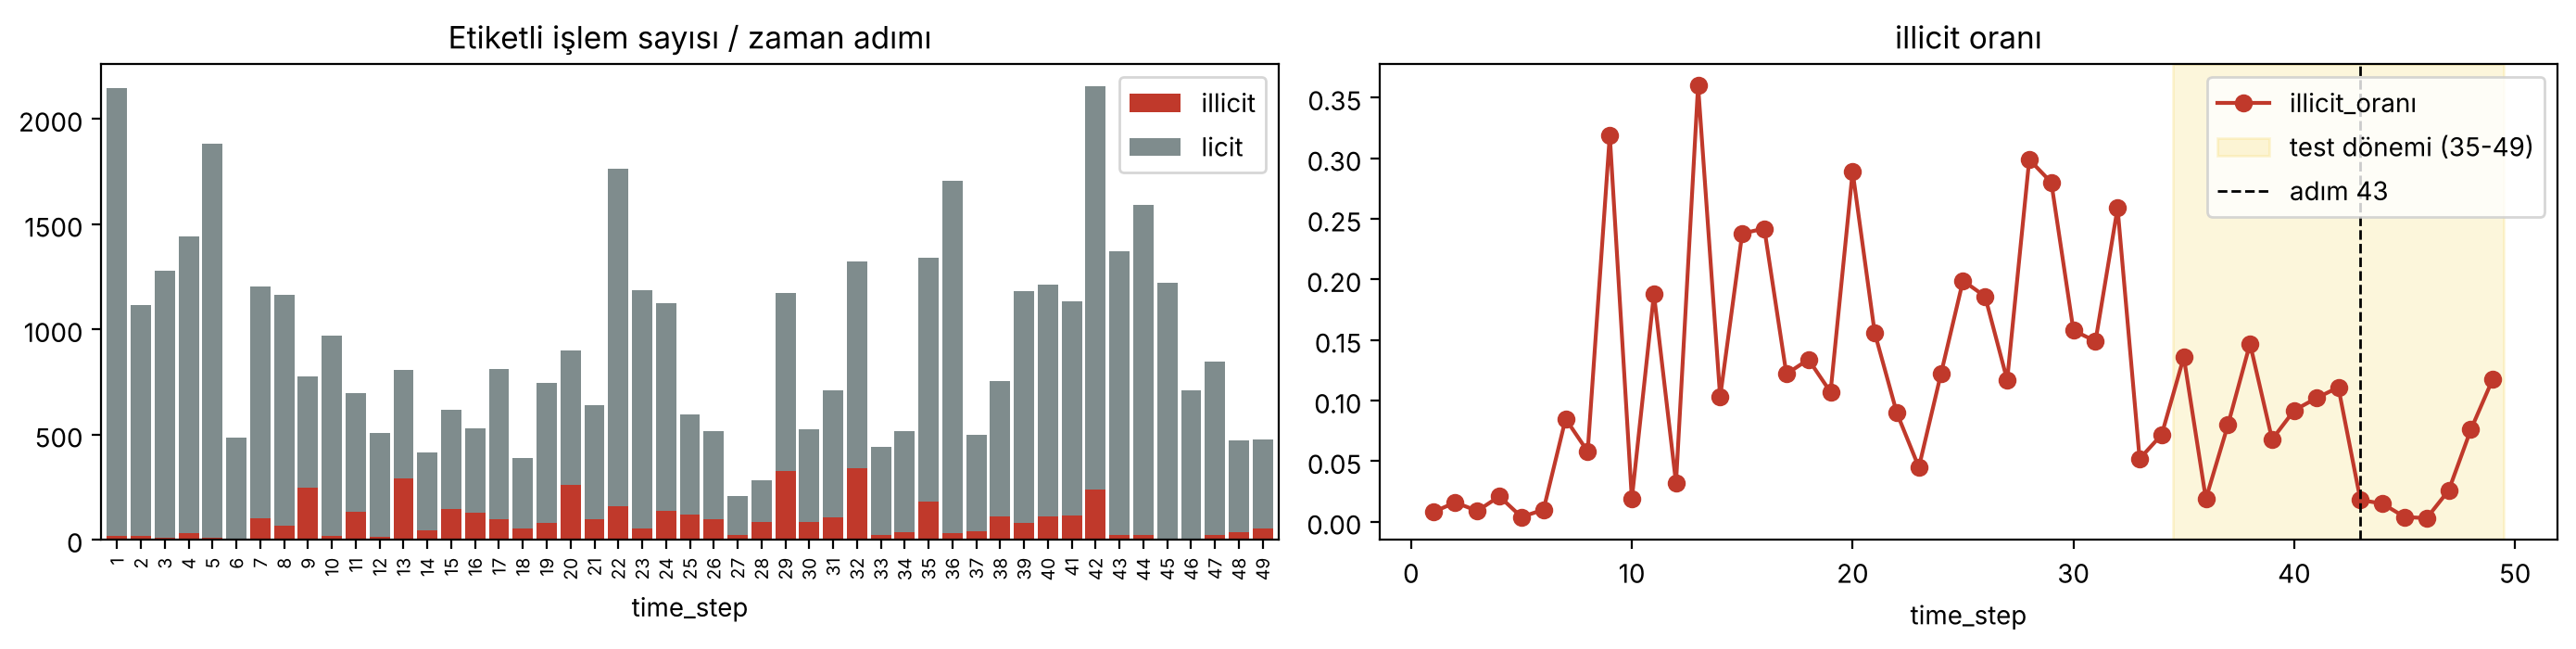

In [18]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
mr2[["illicit", "licit"]].plot.bar(stacked=True, ax=ax[0], color=["#c0392b", "#7f8c8d"], width=0.85)
ax[0].set_title("Etiketli işlem sayısı / zaman adımı"); ax[0].tick_params(axis="x", labelsize=7)
mr2["illicit_oranı"].plot(ax=ax[1], marker="o", color="#c0392b")
ax[1].axvspan(34.5, 49.5, color="#f1c40f", alpha=.15, label="test dönemi (35-49)")
ax[1].axvline(43, ls="--", c="k", lw=1, label="adım 43"); ax[1].legend(); ax[1].set_title("illicit oranı")
plt.tight_layout(); plt.show()

Illicit oranı zaman içinde sabit değil. 43. adımdan sonra illicit işlem sayısı sert biçimde düşüyor (adım 45: 5, adım 46: 2). Aşama 2'deki modelin test performansı tam bu bölgede çökecek.

## MR-3 · Adres aktivitesi: hub cüzdanlar (`union` + `map` + `reduceByKey`)

Her adresin kaç işleme gönderici veya alıcı olarak katıldığını sayıyoruz. Yaklaşık 1.3M kayıt üzerinde çalışan, shuffle'ı gerçekten hissedilen bir iş.

In [19]:
addr_events = (spark.read.parquet(str(PROC / "addr_tx")).rdd.map(lambda r: (r.address, (1, 0)))      # gönderici
         .union(spark.read.parquet(str(PROC / "tx_addr")).rdd.map(lambda r: (r.address, (0, 1)))))  # alıcı
activity = addr_events.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
print("kayıt:", addr_events.count(), "| tekil adres:", activity.count())
pd.DataFrame([(a, s, r, s + r) for a, (s, r) in activity.takeOrdered(8, key=lambda kv: -(kv[1][0] + kv[1][1]))],
             columns=["adres", "gönderen", "alan", "toplam"])

kayıt: 1314241 | tekil adres: 822942


,adres,gönderen,alan,toplam
0,13vHWR3iLsHeYwT42RnuKYNBoVPrKKZgRv,1453,1471,2924
1,1P9RQEr2XeE3PEb44ZE35sfZRRW1JHU8qx,1245,1277,2522
2,366Dgw4pi3rnvu5zizVWZF6nijWxZWc6RA,851,861,1712
3,1FoxBitjXcBeZUS4eDzPZ7b124q3N7QJK7,847,856,1703
4,33fjpQKTzzyQWu6T4PcXUxgbqRbd618u8U,639,639,1278
5,3CD1QW6fjgTwKq3Pj97nty28WZAVkziNom,580,645,1225
6,32bsa2TwxB8y3cK7P1XHDYfdamHTJXSryD,584,585,1169
7,3P9wZeSQN44aozpCzjvCzW3bkM8RdZnYng,568,568,1136


## MR-4 · `reduceByKey` ve `groupByKey`: shuffle maliyeti

`reduceByKey`'in avantajı map-side combine'dan geliyor. Bu avantaj, **aynı partition içinde aynı anahtarın ne sıklıkla tekrarlandığına** bağlı. Bunu iki gerçek iş üzerinde ölçüyoruz ve shuffle write byte'larını Spark UI REST API'sinden okuyoruz:

* **Senaryo A (düşük tekrar):** adres başına olay sayısı. 1.31M kayıt, 823K anahtar, anahtar başına yaklaşık 1.6 kayıt.
* **Senaryo B (yüksek tekrar):** zaman adımı başına cüzdanların toplam BTC hacmi. 921K kayıt, 49 anahtar.

In [20]:
def compare(rdd, label):
    rdd = rdd.cache(); rdd.count()
    rows = []
    for name, job in [("reduceByKey", lambda: rdd.reduceByKey(lambda a, b: a + b).count()),
                      ("groupByKey",  lambda: rdd.groupByKey().mapValues(sum).count())]:
        t = time.time(); n = job(); dt = time.time() - t
        rows.append({"senaryo": label, "yöntem": name, "anahtar": n,
                     "shuffle write KB": max(m["shuffleWriteKB"] for m in stage_metrics(spark, 2)), "süre sn": round(dt, 2)})
    rdd.unpersist()
    return rows

scen_a = addr_events.map(lambda kv: (kv[0], 1))
scen_b = spark.read.parquet(str(PROC / "wallets")).select("time_step", "btc_transacted_total").rdd.map(tuple)
mr4 = pd.DataFrame(compare(scen_a, "A: adres (düşük tekrar)") + compare(scen_b, "B: zaman adımı (yüksek tekrar)"))
mr4

,senaryo,yöntem,anahtar,shuffle write KB,süre sn
0,A: adres (düşük tekrar),reduceByKey,822942,40460.4,4.44
1,A: adres (düşük tekrar),groupByKey,822942,40838.1,7.36
2,B: zaman adımı (yüksek tekrar),reduceByKey,49,2.6,0.82
3,B: zaman adımı (yüksek tekrar),groupByKey,49,7274.5,0.81


**Yorum:** A senaryosunda iki yöntem neredeyse aynı miktarda veri shuffle ediyor. Anahtarların çoğu partition içinde tek kez geçtiği için ön birleştirilecek bir şey yok. B senaryosunda `reduceByKey` her partition'dan anahtar başına yalnızca tek bir kısmi toplam gönderiyor (en fazla 49 × partition sayısı kayıt). `groupByKey` ise 921K değerin tamamını ağ üzerinden taşıyor ve her anahtarın tüm değerlerini reducer'da belleğe alıyor. Pratik sonuç: `reduceByKey` hiçbir zaman daha kötü değil, ama kazancı anahtar kardinalitesiyle ters orantılı. `groupByKey` ise az sayıda sıcak anahtar olduğunda tek bir executor'da bellek taşmasına (skew) en açık yöntem.

`reduceByKey`, partition içinde aynı adresin sayımlarını önceden topladığı için ağa daha az veri gönderiyor. `groupByKey` her `(adres, 1)` çiftini tek tek taşıyor ve tüm değerleri reducer'da belleğe alıyor. Fark, anahtar başına düşen tekrar sayısıyla büyür. Çok aktif "hub" adreslerin olduğu bu veride `groupByKey`, tek bir reducer'da bellek taşmasına (data skew) da yol açabilir.

## Özet

| Adım | Etki |
|---|---|
| Açık şema | 695 MB CSV tek geçişte yüklendi |
| Eksik değer | 965 işlem × 17 özellik birlikte eksik → `aug_missing` göstergesi; doldurma ML pipeline'ında, yalnızca eğitime fit edilerek |
| Gereksiz sütun | `total_BTC` ≡ `out_BTC_total` → çıkarıldı |
| Dönüşüm | BTC/ücret sütunlarına `log1p` (çarpıklık düştü), `fee_rate_sat_b` türetildi, sınıflar `label`'a kodlandı |
| Tekrar | wallets %27 kopya satır, AddrAddr tekrarlı kenarlar ve self-loop'lar temizlendi |
| Format | CSV → Parquet |
| MapReduce | degree, zaman×sınıf sayımı, adres aktivitesi; reduceByKey/groupByKey shuffle karşılaştırması |

In [21]:
spark.stop()